# Tutorial 1 — Reading and visualising common rheological datasets

This tutorial walks through:

1. Reading a
   [**TA Instruments**](https://www.tainstruments.com/) TRIOS `.txt`
   export with a single Creep experiment.
2. Reading a TA Instruments TRIOS `.txt` export with **multiple
   techniques** (amplitude sweep, frequency sweep, flow ramp) in one
   file.
3. Reading an
   [**Anton Paar**](https://www.anton-paar.com/us-en/) RheoCompass
   `.csv` file with `RheoCompassReader`.
4. Inspecting datasets, switching coordinates and visualising results.

:::{seealso}
- File-reader API reference:
  [`hermes_rheo.file_readers`](https://3mcloud.github.io/hermes-rheo/file_readers.html).
- Tutorial 3 covers reading OWChirp experiments — a specialised
  waveform that requires the dedicated
  [`OWChirpAnalysis`](https://3mcloud.github.io/hermes-rheo/transforms.html#module-hermes_rheo.transforms.owchirp_analysis)
  transform.
:::

:::{important}
**How to export TRIOS files for `TriosRheoReader`.**  The reader needs
the full step-header metadata that only two TRIOS export paths write:

- **TRIOS 5 and earlier** → *Send to LIMS*.
- **TRIOS 6.0+** → *Export* → *Export to .txt (Full)*.  The plain
  *Export to .txt* option strips the geometry, calibration and wave
  parameters that `hermes-rheo` needs and will fail to parse.

TRIOS is a free download from
[TA Instruments](https://www.tainstruments.com/support/software-downloads-support/downloads/).
:::

### Import the necessary packages

In [1]:
import matplotlib.pyplot as plt

# One-call helper that returns an ExperimentSet directly.
from hermes_rheo import read_file

# Instrument-specific readers.
from hermes_rheo.file_readers.trios_rheo_txt import TriosRheoReader
from hermes_rheo.file_readers.rheo_compass_csv import RheoCompassReader

# Publication-quality Matplotlib styling — 'science' + 'notebook' with
# LaTeX disabled so the style works on any machine.
from hermes_rheo.visualization import use_science_style
use_science_style()

['science', 'notebook', 'no-latex']

### Specify the filepath for your data

In [2]:
import os

# Get the directory of this notebook (works when the notebook is opened
# in-place; falls back to the current working directory otherwise).
current_dir = os.path.dirname(os.path.abspath("__file__"))

# TRIOS .txt fixtures
filepath_creep_dataset = os.path.join(
    current_dir, "tutorial_data", "tutorial_1", "creep_experiment.txt"
)
filepath_multi_technique_dataset = os.path.join(
    current_dir, "tutorial_data", "tutorial_1", "multi_technique.txt"
)

# Anton Paar RheoCompass .csv fixture (borrowed from tests/fileio/test_data/).
filepath_anton_paar = os.path.join(
    current_dir, "tutorial_data", "tutorial_1", "anton_paar_tts.csv"
)

## Reading a single-technique TRIOS file

We use `hermes_rheo.read_file` with the TRIOS reader to convert the
`.txt` export directly into an `ExperimentSet`.  For a Creep step the
resulting dataset has `time` as its independent variable and `strain` as
its dependent variable — ready to plot without further processing.

In [3]:
creep_dataset = read_file(
    filepath_creep_dataset,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
print(creep_dataset)

ExperimentSet
-------------

Summary
-------
Number of Experiments: 1

Varied Conditions
----------------

index	n_rep	method	Data Types	
0	1	Creep - 1	strain(%)=f(time[min]) (483 points)	




#### Visualize the processed data

ExperimentSet
-------------

Summary
-------
Number of Experiments: 1

Varied Conditions
----------------

index	n_rep	method	Data Types	
0	1	Creep - 1	strain(%)=f(time[min]) (483 points)	




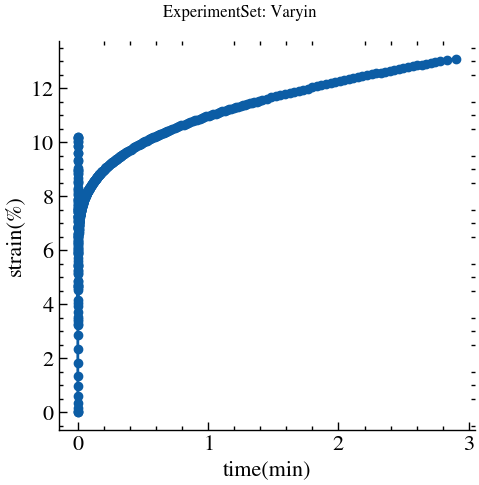

In [4]:
fig_creep, axs_creep = creep_dataset.visualize(expand_replicates=True, marker='o')

## Reading a multi-technique TRIOS file

A single TRIOS file can contain multiple techniques in sequence (e.g. an
amplitude sweep, a frequency sweep and a flow ramp).  Each measurement
gets a different natural `(independent, dependent)` pair:

- Amplitude sweep → `storage modulus=f(oscillation strain (cmd))`
- Frequency sweep → `storage modulus=f(angular frequency)`
- Flow ramp → `viscosity=f(shear rate)`

`ExperimentSet` enforces consistency across measurements, so wrapping a
mixed-technique file directly raises `InconsistentMeasurementsError`.

:::{tip}
For mixed-technique files use `default_coords="legacy-temperature"` on
the reader — every measurement gets the same active coordinate pair, so
the `ExperimentSet` is consistent.  Call `switch_coordinates()` on any
specific measurement afterwards to inspect its natural axes.
:::

In [5]:
multi_technique_dataset = read_file(
    filepath_multi_technique_dataset,
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
    default_coords="legacy-temperature",   # keep the mixed file consistent
)
print(multi_technique_dataset)

ExperimentSet
-------------

Summary
-------
Number of Experiments: 3

Varied Conditions
-----------------
method

index	n_rep	method	Data Types	
0	1	Amplitude sweep - 1	Temperature(°C)=f(Temperature[°C]) (29 points)	
1	1	Frequency sweep - 2	Temperature(°C)=f(Temperature[°C]) (29 points)	
2	1	Flow ramp - 3	Temperature(°C)=f(Temperature[°C]) (223 points)	




### Access a specific experiment in the dataset

Index the `ExperimentSet` as `experiment_set[experiment_idx][repetition_idx].datasets[dataset_idx]`.
We grab the amplitude-sweep experiment and switch its coordinates to the
scientifically natural pair before plotting.

In [6]:
# [experiment_idx][repetition_idx].datasets[dataset_idx]
amplitude_sweep_experiment = multi_technique_dataset[0][0].datasets[0]

# Switch to the natural amplitude-sweep view: G' vs oscillation strain (cmd).
amplitude_sweep_experiment.switch_coordinates(
    independent_name="oscillation strain (cmd)",
    dependent_name="storage modulus",
)
print(amplitude_sweep_experiment)

OneDimensionalCompositeDataset
------------------------------
Dataset Source: tutorial_data/tutorial_1/multi_technique.txt

Dependent Variable Data Properties: ndim=1, size=29 (29 bytes), shape=(29,)
Dependent Variable Labels: storage modulus(MPa)

Independent Variable Data Properties: n=1, lengths=[29]
Independent Variable Labels: oscillation strain (cmd)(%)

Values of storage modulus (MPa) as a function of oscillation strain (cmd) (%)

oscillation strain (cmd) = [  +0.0099   +0.0139 ...  +84.4592 +117.5245]
storage modulus          = [+0.0184 +0.0185 ... +0.0011 +0.0006]


#### Visualize specific set of data

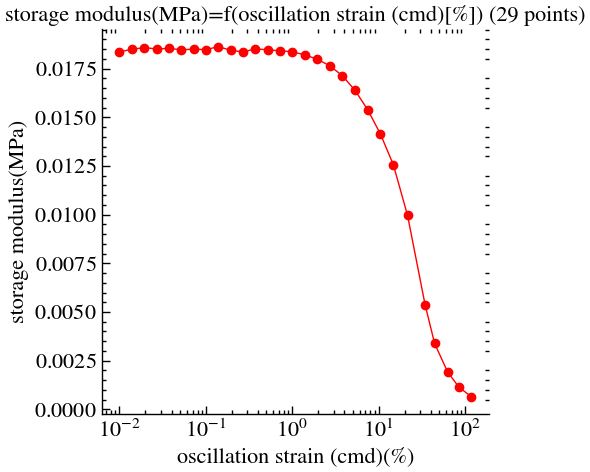

In [7]:
fig_sweep, ax_sweep = amplitude_sweep_experiment.visualize(
    marker="o", linewidth=1, color="red",
)
fig_sweep.set_size_inches(5, 5)
ax_sweep.set_xscale("log")

#### Access different coordinate in the experiment

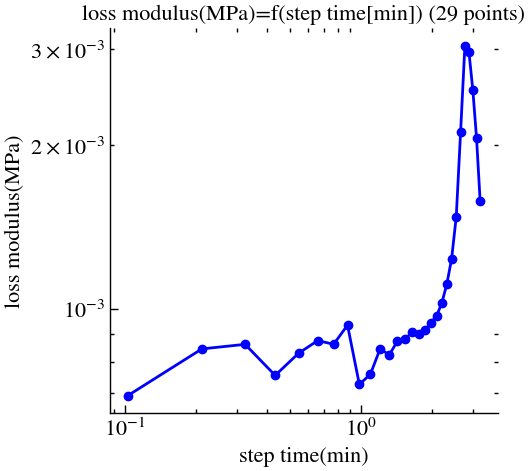

In [8]:
amplitude_sweep_experiment.switch_coordinates(
    independent_name="step time", dependent_name="loss modulus",
)
fig3, ax3 = amplitude_sweep_experiment.visualize(marker="o", color="blue")
fig3.set_size_inches(5, 5)
ax3.set_xscale("log")
ax3.set_yscale("log")

#### Access the independent and dependent variables of the dataset

In [9]:
loss_modulus = amplitude_sweep_experiment.x_values
step_time = amplitude_sweep_experiment.y_values

print('loss modulus = ',loss_modulus)
print('step time = ',step_time)

loss modulus =  [+0.1029 +0.2119 ... +3.0939 +3.2046]
step time =  [+0.0007 +0.0008 ... +0.0021 +0.0016]


#### Access different experiment in the dataset

In [10]:
frequency_sweep_experiment = multi_technique_dataset[1][0].datasets[0]
flow_ramp_experiment = multi_technique_dataset[2][0].datasets[0]

# Switch each to its natural view.
frequency_sweep_experiment.switch_coordinates(
    independent_name="angular frequency", dependent_name="storage modulus",
)
flow_ramp_experiment.switch_coordinates(
    independent_name="shear rate", dependent_name="viscosity",
)

print(frequency_sweep_experiment)
print()
print(flow_ramp_experiment)

OneDimensionalCompositeDataset
------------------------------
Dataset Source: tutorial_data/tutorial_1/multi_technique.txt

Dependent Variable Data Properties: ndim=1, size=29 (29 bytes), shape=(29,)
Dependent Variable Labels: storage modulus(MPa)

Independent Variable Data Properties: n=1, lengths=[29]
Independent Variable Labels: angular frequency(rad/s)

Values of storage modulus (MPa) as a function of angular frequency (rad/s)

angular frequency = [+628.3185 +452.1964 ...   +0.0873   +0.0628]
storage modulus   = [+0.0180 +0.0166 ... +0.0150 +0.0149]

OneDimensionalCompositeDataset
------------------------------
Dataset Source: tutorial_data/tutorial_1/multi_technique.txt

Dependent Variable Data Properties: ndim=1, size=223 (223 bytes), shape=(223,)
Dependent Variable Labels: viscosity(Pa.s)

Independent Variable Data Properties: n=1, lengths=[223]
Independent Variable Labels: shear rate(1/s)

Values of viscosity (Pa.s) as a function of shear rate (1/s)

shear rate = [+0.0009 +0.00

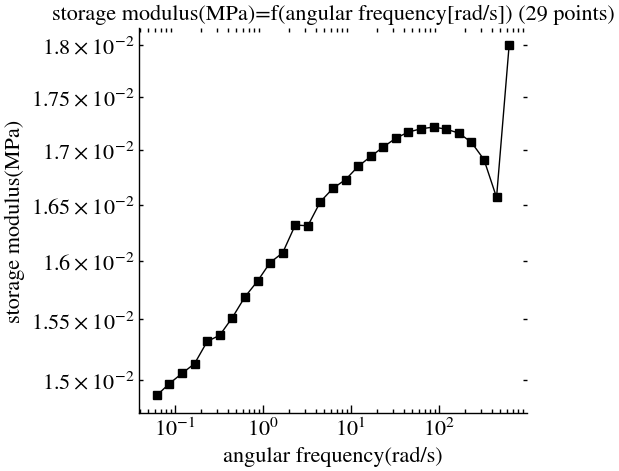

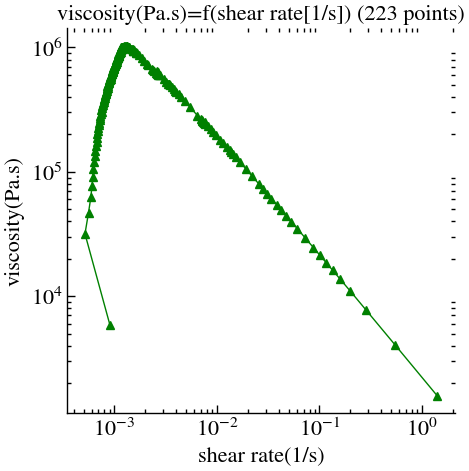

In [11]:
# Visualize frequency sweep experiment
fig_freq, ax_freq = frequency_sweep_experiment.visualize(
    marker="s", linewidth=1, color="black",
)
fig_freq.set_size_inches(5, 5)
ax_freq.set_xscale("log")
ax_freq.set_yscale("log")

# Visualize flow ramp experiment
fig_flow, ax_flow = flow_ramp_experiment.visualize(
    marker="^", linewidth=1, color="green",
)
fig_flow.set_size_inches(5, 5)
ax_flow.set_yscale("log")
ax_flow.set_xscale("log")

## Reading an Anton Paar RheoCompass file

Beyond [TA Instruments](https://www.tainstruments.com/) TRIOS,
`hermes_rheo` ships instrument-specific readers for the commonly
used rheometer file formats:

| Instrument / software | Reader class |
|---|---|
| [TA Instruments](https://www.tainstruments.com/) TRIOS `.txt` (*Export to LIMS* or, from TRIOS 6.0+, *Export to .txt (Full)*)  | `TriosRheoReader` |
| [Anton Paar](https://www.anton-paar.com/us-en/) RheoCompass `.csv`     | `RheoCompassReader` |

Every reader follows the same contract: pass its class to
`hermes_rheo.read_file` and it returns an `ExperimentSet` ready
to inspect.  Below we read an
[Anton Paar](https://www.anton-paar.com/us-en/) TTS frequency-sweep
sequence exported as `.csv`.

:::{note}
`RheoCompassReader` picks its default coordinates from the column set
(oscillatory sweep, flow sweep, or transient fallback) — no `default_coords`
opt-in is needed here.
:::

In [12]:
anton_paar_dataset = read_file(
    filepath_anton_paar,
    file_reader=RheoCompassReader,
    create_composite_datasets=True,
)
print(anton_paar_dataset)

ExperimentSet
-------------

Summary
-------
Number of Experiments: 33

Varied Conditions
-----------------
method

index	n_rep	method	Data Types	
0	1	Interval 1 (Fs - 100.11)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
1	1	Interval 1 (Fs - 94.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
2	1	Interval 1 (Fs - 89.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
3	1	Interval 1 (Fs - 84.97)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
4	1	Interval 1 (Fs - 79.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
5	1	Interval 1 (Fs - 74.98)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
6	1	Interval 1 (Fs - 69.97)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
7	1	Interval 1 (Fs - 64.97)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
8	1	Interval 1 (Fs - 59.95)	storage modulus([MPa])=f(angular frequency[[rad/s]]) (11 points)	
9	1	In

Each interval in the RheoCompass CSV becomes one measurement.  This file
is an isothermal frequency-sweep TTS block, so every measurement is a
`storage modulus=f(angular frequency)` sweep.  Let's plot the first one:

angular frequency -> storage modulus


Text(0.5, 1.0, 'Anton Paar RheoCompass — first frequency sweep')

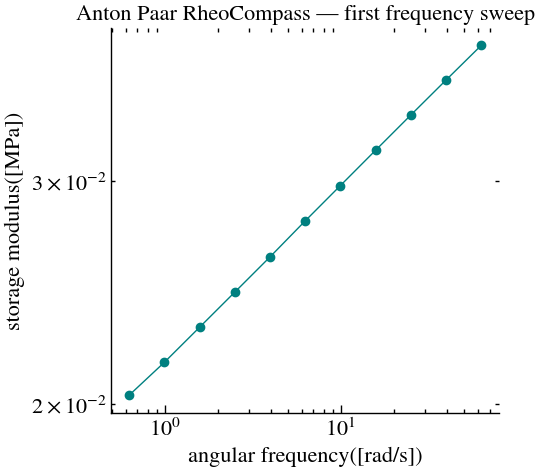

In [13]:
first_sweep = anton_paar_dataset[0][0].datasets[0]
print(
    first_sweep.independent_variable_name,
    "->",
    first_sweep.dependent_variable_name,
)

fig_ap, ax_ap = first_sweep.visualize(marker="o", linewidth=1, color="teal")
fig_ap.set_size_inches(5, 5)
ax_ap.set_xscale("log")
ax_ap.set_yscale("log")
ax_ap.set_title("Anton Paar RheoCompass — first frequency sweep")